
# SVM Baseline for Malware Detection

## Objectives

The objective of this notebook is to develop a Support Vector Machine (SVM) baseline model for malware detection using the preprocessed BODMAS dataset.

The model classifies Windows executable files into two categories:
- 0: Benign
- 1: Malicious

The main objectives are:
- Load and validate the dataset.
- Analyze the distribution of the target classes.
- Apply feature selection to reduce dimensionality.
- Build an SVM classification model.
- Optimize the model hyperparameters using cross-validation.
- Evaluate the model using classification metrics.
- Save the trained model for future adversarial experiments.


## 1. Data Integration

### 1.1 Loading the Preprocessed Dataset

The preprocessed BODMAS dataset is loaded from the processed-data directory. Data preprocessing and the train/test split have already been performed in an earlier stage of the project.

Each sample is represented by 2,381 numerical features. The dataset is provided in four arrays:

- `X_train` and `y_train`: features and labels used for model training and hyperparameter tuning.
- `X_test` and `y_test`: features and labels reserved for the final evaluation.

The test set is kept separate to ensure an unbiased evaluation of the model's performance.

In [1]:
from pathlib import Path
import numpy as np
import joblib

# Path to the preprocessed dataset
DATA_DIR = Path('../../data/processed/bodmas')

X_train = np.load(DATA_DIR / 'X_train.npy')
y_train = np.load(DATA_DIR / 'y_train.npy')

X_test = np.load(DATA_DIR / 'X_test.npy')
y_test = np.load(DATA_DIR / 'y_test.npy')

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (107548, 2381)
Training labels: (107548,)
Testing features: (26887, 2381)
Testing labels: (26887,)


### 1.2 Dataset Integrity and Shape

Before training the machine-learning model, we verify that the loaded arrays are structurally consistent and contain valid numerical values.

The following checks are performed:

- Verify that each feature matrix has the same number of samples as its corresponding label vector.
- Ensure that training and testing datasets have the same number of features.
- Check for missing (`NaN`) and infinite values.
- Verify that the target contains the expected binary labels (0 and 1).
- Examine the distribution of the target classes in both datasets.

These checks help ensure that the data is valid and ready for model training.

In [2]:
# Check dataset dimensions
assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)

# Check feature consistency
assert X_train.shape[1] == X_test.shape[1]

# Check missing and infinite values
print("NaN values in training:", np.isnan(X_train).sum())
print("NaN values in testing:", np.isnan(X_test).sum())

print("Infinite values in training:", np.isinf(X_train).sum())
print("Infinite values in testing:", np.isinf(X_test).sum())

# Check label values
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

# Check class distribution
print("\nTraining class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting class distribution:")
print(np.unique(y_test, return_counts=True))

# Verify that the data is valid
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

print("\nData validation completed successfully.")

NaN values in training: 0
NaN values in testing: 0
Infinite values in training: 0
Infinite values in testing: 0
Training labels: [0 1]
Testing labels: [0 1]

Training class distribution:
(array([0, 1], dtype=int32), array([61714, 45834]))

Testing class distribution:
(array([0, 1], dtype=int32), array([15428, 11459]))

Data validation completed successfully.


### 1.3 Label Distribution

The distribution of benign and malicious samples is examined
to identify potential class imbalance.

This analysis is important because an imbalanced dataset may
affect the learning process and classification performance.

The class distribution is examined separately for the training
and testing sets to verify the consistency of the data splits.

In [3]:
import pandas as pd

train_distribution = pd.Series(y_train).value_counts().sort_index()
test_distribution = pd.Series(y_test).value_counts().sort_index()

distribution = pd.DataFrame({
    "Training Set": train_distribution,
    "Testing Set": test_distribution
})

distribution.index = ["Benign", "Malicious"]

display(distribution)

,Training Set,Testing Set
Benign,61714,15428
Malicious,45834,11459



### 2.1 Feature Selection Strategy

The preprocessed BODMAS dataset contains 2,381 numerical features.

In this implementation, all available features are initially used for training.

A `VarianceThreshold` transformer is included in the SVM Pipeline to remove constant features, as they do not provide useful information for classification.

Therefore, the model uses all available non-constant features without applying a statistical feature ranking method.



### 2.2 Feature Selection Configuration

The model uses all available features without selecting a fixed number of features.

The `VarianceThreshold(threshold=0.0)` transformer removes features with zero variance (constant features).

**Why use a Pipeline?**

The Pipeline combines feature filtering and classification into a single workflow. It ensures that the same processing steps are applied during training, cross-validation and prediction.


In [4]:
# Feature Configuration

n_features = X_train.shape[1]

print("Total number of available features:", n_features)
print("Feature selection: Disabled")
print("Feature configuration: All features")

Total number of available features: 2381
Feature selection: Disabled
Feature configuration: All features


## 3. Support Vector Machine (SVM)

### 3.1 Why LinearSVC?

We selected **LinearSVC** as our baseline model for malware detection because:

**High-dimensional data**: It is suitable for datasets with many features, such as BODMAS (2,381 features).

**Efficiency**: Its linear decision function makes it efficient for large datasets.

**Regularization**: The parameter C controls the balance between model simplicity and classification errors.

LinearSVC provides a good starting point for binary classification and comparison with other models.

### 3.2 Regularization Parameter

The regularization parameter `C` controls the balance between model simplicity and training errors:
- Small `C`: stronger regularization.
- Large `C`: weaker regularization.




### 3.3 SVM Pipeline Configuration

The `Pipeline` combines two steps:

1. `VarianceThreshold(threshold=0.0)`: removes constant features.
2. `LinearSVC`: performs the binary classification between benign and malicious files.

The LinearSVC classifier uses the following parameters:

- `C`: regularization parameter, optimized using GridSearchCV.
- `class_weight='balanced'`: adjusts class weights according to their distribution.
- `dual=False`: uses the primal optimization formulation.
- `max_iter=5000`: sets the maximum number of iterations.
- `random_state=42`: ensures reproducibility.

The input features have already been scaled during the previous preprocessing stage.


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_selection import VarianceThreshold

# SVM pipeline using all preprocessed features
svm_pipeline = Pipeline([
    ('remove_constant', VarianceThreshold(threshold=0.0)),
    ('svm', LinearSVC(
        class_weight='balanced',
        dual=False,
        max_iter=5000,
        random_state=42
    ))
])

print("Selected model: LinearSVC")
print("Number of input features:", X_train.shape[1])
print("Feature selection: All features")
print("Scaling: Already performed during preprocessing")
print("Parameters:", svm_pipeline)

Selected model: LinearSVC
Number of input features: 2381
Feature selection: All features
Scaling: Already performed during preprocessing
Parameters: Pipeline(steps=[('remove_constant', VarianceThreshold()),
                ('svm',
                 LinearSVC(class_weight='balanced', dual=False, max_iter=5000,
                           random_state=42))])


## 4. Model Training and Hyperparameter Tuning


### 4.1 Tuning Strategy

The regularization parameter `C` is optimized using `GridSearchCV`.

Three candidate values are tested:

- `0.01`
- `0.1`
- `1.0`

The configuration with the highest F1-score during cross-validation is selected.

The search uses:
- **Cross-validation:** 3 folds using StratifiedKFold.
- **Scoring metric:** F1-score.
- **Training sample:** 30,000 samples selected from the training set.

The best configuration obtained is:

- **Classifier:** LinearSVC.
- **Regularization parameter:** C = 0.01.
- **Features:** All available non-constant features.


In [6]:
# Hyperparameter search configuration

C_GRID = [0.01, 0.1, 1.0]

CV_FOLDS = 3
GRID_SAMPLE = 30000
SCORING = 'f1'
SEED = 42

print("Feature configuration: All available features")
print("C candidates:", C_GRID)
print("Cross-validation folds:", CV_FOLDS)
print("Grid search sample:", GRID_SAMPLE)
print("Scoring:", SCORING)

Feature configuration: All available features
C candidates: [0.01, 0.1, 1.0]
Cross-validation folds: 3
Grid search sample: 30000
Scoring: f1



### 4.2 GridSearchCV Configuration and Training

`GridSearchCV` evaluates the three candidate values of the regularization parameter `C` using 3-fold stratified cross-validation.

A stratified sample of 30,000 training samples is used for the hyperparameter search.

The training process follows these steps:

1. Create a stratified sample from the training set.
2. Divide the sample into three folds using `StratifiedKFold`.
3. Remove constant features using `VarianceThreshold`.
4. Train LinearSVC with each candidate value of `C`.
5. Evaluate each configuration using the F1-score.
6. Select the configuration with the best cross-validation score.

The selected Pipeline is then trained again using the complete training dataset (`X_train` and `y_train`).


In [7]:
import time

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.model_selection import train_test_split

# 1. Create a stratified sample for GridSearchCV
if GRID_SAMPLE and GRID_SAMPLE < len(y_train):

    X_grid, _, y_grid, _ = train_test_split(
        X_train,
        y_train,
        train_size=GRID_SAMPLE,
        stratify=y_train,
        random_state=SEED
    )

else:
    X_grid, y_grid = X_train, y_train

print("Grid search training samples:", len(y_grid))

# 2. Define cross-validation
cv_strategy = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

# 3. Define GridSearchCV
param_grid = {
    'svm__C': C_GRID
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring=SCORING,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

# 4. Perform hyperparameter search
start_time = time.time()

grid_search.fit(X_grid, y_grid)

grid_search_time = time.time() - start_time

print("\nGrid Search completed!")
print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))
print(f"Grid search time: {grid_search_time:.2f} seconds")

# 5. Train the selected model on the complete training set
best_svm_model = grid_search.best_estimator_

start_time = time.time()

best_svm_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("\nFinal model training completed!")
print("Selected C:", grid_search.best_params_['svm__C'])
print("Number of input features:", X_train.shape[1])
print(f"Final training time: {training_time:.2f} seconds")

Grid search training samples: 30000
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Grid Search completed!
Best parameters: {'svm__C': 0.01}
Best CV F1-score: 0.9808
Grid search time: 920.50 seconds

Final model training completed!
Selected C: 0.01
Number of input features: 2381
Final training time: 470.38 seconds



### 4.3 Optimal Hyperparameter Selection

After GridSearchCV completes, the best configuration is obtained using `best_estimator_`.

The selected model uses:

- **Classifier:** LinearSVC.
- **Best regularization parameter:** C = 0.01.
- **Cross-validation F1-score:** 0.9808.

The selected Pipeline is then fitted on the complete training dataset.

The resulting model is stored in `best_svm_model` and used for the final evaluation.


In [8]:
print("Final model: LinearSVC")
print("Best C:", grid_search.best_params_['svm__C'])
print("Cross-validation F1:", round(grid_search.best_score_, 4))
print("Features:", X_train.shape[1])
print("Training time:", round(training_time, 2), "seconds")

Final model: LinearSVC
Best C: 0.01
Cross-validation F1: 0.9808
Features: 2381
Training time: 470.38 seconds



## 5. Model Evaluation

The trained SVM model is evaluated on the test dataset (`X_test` and `y_test`).

The following metrics are calculated:

- **Accuracy:** measures the proportion of correctly classified samples.
- **Precision:** measures how many samples predicted as malicious are actually malicious.
- **Recall:** measures how many actual malicious samples are correctly detected.
- **F1-score:** represents the balance between precision and recall.
- **ROC-AUC:** measures the model's ability to distinguish between benign and malicious samples using decision scores.

These metrics provide an overall assessment of the model's classification performance.


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
import matplotlib.pyplot as plt

# Predict class labels and obtain decision scores
y_pred = best_svm_model.predict(X_test)
y_scores = best_svm_model.decision_function(X_test)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred)
svm_precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_roc_auc = roc_auc_score(y_test, y_scores)

# Display the results
svm_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        svm_accuracy,
        svm_precision,
        svm_recall,
        svm_f1,
        svm_roc_auc
    ]
})

display(svm_metrics.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Accuracy,0.9897
1,Precision,0.9839
2,Recall,0.9921
3,F1-score,0.9880
4,ROC-AUC,0.9972


### 5.1 Evaluation Metrics Analysis

The SVM model achieves an accuracy of **98.28%** and a ROC-AUC of **99.72%**, indicating strong overall classification performance.

For the malicious class, the model obtains:
- **Precision: 98.39%** – most files predicted as malicious are actually malicious.
- **Recall: 99.21%** – the model successfully detects most malicious files.
- **F1-score: 98.80%** – a strong balance between precision and recall.

The high recall is particularly important in malware detection because it means that relatively few malicious samples are missed.

### 5.2 Classification Report

The classification report provides a detailed view of the model's performance for both classes: Benign and Malicious.

In [10]:
print("SVM Classification Report")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malicious"],
        digits=4,
        zero_division=0
    )
)

SVM Classification Report
              precision    recall  f1-score   support

      Benign     0.9941    0.9879    0.9910     15428
   Malicious     0.9839    0.9921    0.9880     11459

    accuracy                         0.9897     26887
   macro avg     0.9890    0.9900    0.9895     26887
weighted avg     0.9898    0.9897    0.9897     26887



The model performs well on both classes:

- **Benign:** F1-score of 99.10%.
- **Malicious:** F1-score of 98.80%.

The results show that the SVM model maintains balanced performance across benign and malicious samples, with slightly better results for the benign class.

### 5.3 Confusion Matrix Analysis

The confusion matrix helps identify the number of correctly and incorrectly classified samples.

Confusion Matrix Values
True Negatives  (TN): 15242
False Positives (FP): 186
False Negatives (FN): 90
True Positives  (TP): 11369


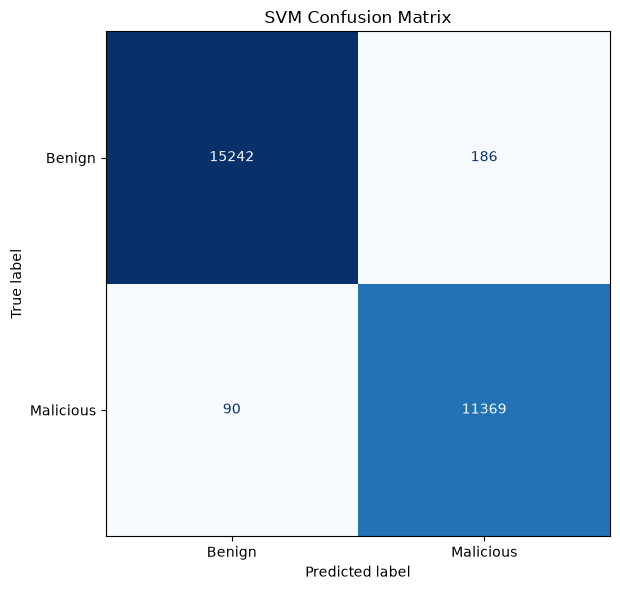

In [11]:
# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix Values")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malicious"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix provides a breakdown of the model's classification results:

- **True Negatives (15242)**: Benign samples correctly classified as benign.
- **False Positives (186)**: Benign samples incorrectly classified as malicious.
- **False Negatives (90)**: Malicious samples incorrectly classified as benign.
- **True Positives (11369)**: Malicious samples correctly classified as malicious.


### 5.4 ROC Curve Analysis

The ROC curve evaluates the model's ability to distinguish between benign and malicious files at different classification thresholds.

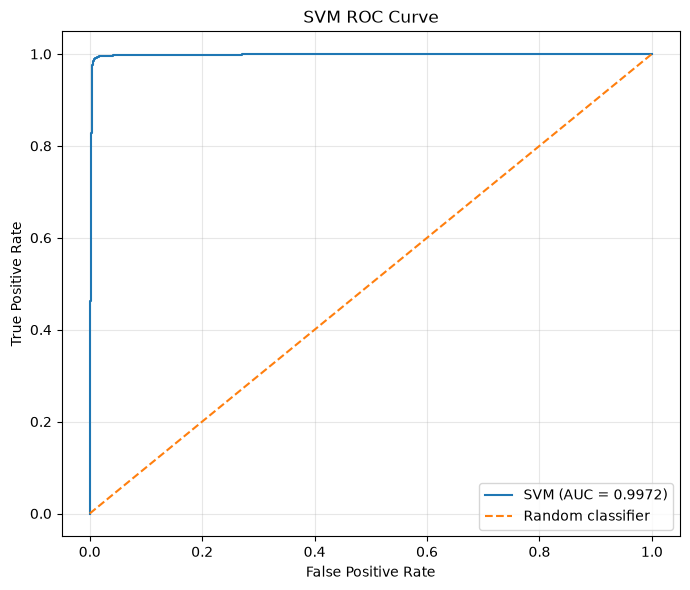

In [12]:
# Calculate ROC curve points from SVM decision scores
fpr, tpr, thresholds = roc_curve(y_test, y_scores, pos_label=1)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"SVM (AUC = {svm_roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The SVM model achieves a ROC-AUC score of **99.72%**. This indicates an excellent ability to distinguish between benign and malicious samples.

The ROC curve is close to the upper-left corner, showing a high True Positive Rate and a low False Positive Rate.

## 6. Model Saving



In [13]:
from pathlib import Path
import joblib

# Create the output directory if it does not already exist
MODEL_DIR = Path("../../models/baselines")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "svm_baseline.joblib"

# Save the complete fitted pipeline
joblib.dump(best_svm_model, MODEL_PATH)

print(f"SVM model saved successfully to: {MODEL_PATH}")

SVM model saved successfully to: ..\..\models\baselines\svm_baseline.joblib



## 7. Conclusion

The SVM baseline achieves strong performance on the BODMAS dataset, with:

- **Accuracy:** 98.97%.
- **F1-score (Malicious):** 98.80%.
- **ROC-AUC:** 99.72%.

The model successfully detects most malicious samples while maintaining good classification performance on benign files